# Lab 02: Ethics, Law, and Responsible Data Collection

*INFO 4617/5617 · Week 2 · Chapter 2, [Ethics, Law, and Responsible Data Collection](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-02-ethics.html)*

Today we build the habits the chapter asks for before any collection: a User-Agent that says who we are, a `robots.txt` read properly, a pause between requests, and one loop that does all three. Our case is the news business, where the chapter says `robots.txt` has become a front line: we read the New York Times's file line by line, then ask six newsrooms which AI crawlers they let in. After each step, a **💬 Discuss** box holds questions to talk over before the next one; click it to open it.

**Before class:** open this notebook in the `webdata` environment (chapter 1), and have your email address ready for the User-Agent.

On Friday, run every cell above where we stopped (**Run → Run All Above Selected Cell**).

> **Instructor key.** Every cell is filled in and was run against the live sites on 2026-10-21, in Python 3.14.8, following the textbook at commit `d9306b7`. `robots.txt` files change without notice and have no dated versions to ask for, so the counts and the allowed/blocked tables in Steps 2, 3 and 5 may differ on a rerun, and the timings in Steps 6 and 7 vary by a few tenths of a second. The 403s in Step 8, and the bot-detection page behind them, depend on the network a request comes from: from campus, a site may answer differently. Python before 3.14.5 parses `robots.txt` by older rules (Step 3), so it gives different answers for some rows. Every cell was run live.

## Step 0 — Set up (5 minutes)

Import what we need, then define the User-Agent every request will send. The chapter's [Responsible Request Headers](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-02-ethics.html#responsible-request-headers) section asks for a name, a version, and a way to reach you, in the form Wikimedia's [User-Agent policy](https://foundation.wikimedia.org/wiki/Policy:Wikimedia_Foundation_User-Agent_Policy) gives: `<client name>/<version> (<contact information>)`. We'll also parse `robots.txt` files with [`urllib.robotparser`](https://docs.python.org/3/library/urllib.robotparser.html), part of Python itself, so print which Python you have: in Step 3 it changes the answers.

In [1]:
# Import sys, time, requests, pandas (as pd), matplotlib.pyplot (as plt), and RobotFileParser from urllib.robotparser
# Define HEADERS: a dict whose "User-Agent" is "WebDataScience/1.0 (your-email@colorado.edu)", with your email
# Print HEADERS, and the Python version (the first word of sys.version)
import sys
import time
import requests
import pandas as pd
import matplotlib.pyplot as plt
from urllib.robotparser import RobotFileParser

HEADERS = {"User-Agent": "WebDataScience/1.0 (your-email@colorado.edu)"}
print(HEADERS)
print(f"Python {sys.version.split()[0]}")

{'User-Agent': 'WebDataScience/1.0 (your-email@colorado.edu)'}
Python 3.14.8


<details>
<summary>💬 Discuss</summary>

- In week 1 we sent this header to Wikipedia because the chapter told us to, and it promised to explain why later. Who reads it, and when?
- Every request you send this week carries your email address. What does that commit you to?
- Nothing stops a script from copying a browser's User-Agent instead. Why does the chapter ask you to name yourself?

</details>

## Step 1 — What a server sees (5 minutes)

A server can't see your code, only your request. [httpbin.org/headers](https://httpbin.org/#/Request_inspection/get_headers) answers every request with the headers it received, so we can read our request the way a server does. Ask it twice, once with no headers and once with [`headers=HEADERS`](https://requests.readthedocs.io/en/latest/user/quickstart/#custom-headers), and compare the User-Agents. Then ask for week 1's Wikipedia article with no headers at all. These are the lab's only requests sent without `HEADERS`, on purpose.

In [2]:
# Request https://httpbin.org/headers twice, with no headers (plain) and with HEADERS (named); keep each .json()
# Print the "User-Agent" inside each one's "headers"
# Request https://en.wikipedia.org/wiki/University_of_Colorado_Boulder with no headers; print its status code
plain = requests.get("https://httpbin.org/headers").json()
named = requests.get("https://httpbin.org/headers", headers=HEADERS).json()
print(f"No headers:   {plain['headers']['User-Agent']}")
print(f"With HEADERS: {named['headers']['User-Agent']}")

response = requests.get("https://en.wikipedia.org/wiki/University_of_Colorado_Boulder")
print(f"Wikipedia, no headers: {response.status_code}")

No headers:   python-requests/2.34.2
With HEADERS: WebDataScience/1.0 (your-email@colorado.edu)


Wikipedia, no headers: 403


<details>
<summary>💬 Discuss</summary>

- In week 1 Wikipedia refused `requests`' default User-Agent with a 403. Is refusing anonymous clients fair for a site that wants to be read?
- Print `plain["headers"]`, the whole dictionary the echo sent back. What else did the server learn about us besides the User-Agent?
- The default names the library and its version but not you. Whom can a site operator contact about a misbehaving `python-requests` client?

</details>

## Step 2 — Read a robots.txt (7 minutes)

A [`robots.txt`](https://www.robotstxt.org/) file lives at the root of a site and says which parts automated agents may fetch: `User-agent` lines name the crawlers a group of rules is for, then `Disallow` and `Allow` lines give paths (chapter, [Technical Norms](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-02-ethics.html#technical-norms-robots.txt)). The chapter compares the New York Times's file with Wikipedia's and Reddit's. Fetch the Times's file with `HEADERS`, print its status code, and split it into lines. Before any rules, it opens with a notice; print it. Then list the crawlers the file names.

In [3]:
# Fetch https://www.nytimes.com/robots.txt with HEADERS; print the status code
# Split the text into lines; print the lines among the first 15 that start with "#"
response = requests.get("https://www.nytimes.com/robots.txt", headers=HEADERS)
print(f"Status: {response.status_code}")
lines = response.text.splitlines()
for line in lines[:15]:
    if line.startswith("#"):
        print(line)

Status: 200
# New York Times content is made available for your personal, non-commercial
# use subject to our Terms of Service here:
# https://help.nytimes.com/hc/en-us/articles/115014893428-Terms-of-Service.
# Use of any device, tool, or process designed to data mine or scrape the content
# using automated means is prohibited without prior written permission from
# The New York Times Company.  Prohibited uses include but are not limited to:
# (1) text and data mining activities under Art. 4 of the EU Directive on Copyright in
# the Digital Single Market;
# (2) the development of any software, machine learning, artificial intelligence (AI),
# and/or large language models (LLMs);
# (3) creating or providing archived or cached data sets containing our content to others; and/or
# (4) any commercial purposes.
# Contact https://nytlicensing.com/contact/ for assistance.


In [4]:
# Collect into agents the name after the colon on every line that starts with "User-agent"
# Print how many names there are, how many are different (set), and the first eight
agents = []
for line in lines:
    if line.lower().startswith("user-agent"):
        agents.append(line.split(":", 1)[1].strip())
print(f"{len(agents)} User-agent lines, {len(set(agents))} different crawlers, such as {agents[:8]}")

69 User-agent lines, 68 different crawlers, such as ['*', 'Googlebot', 'Googlebot', 'AliyunSecBot', 'Amazonbot', 'anthropic-ai', 'Applebot-Extended', 'archive.org_bot']


<details>
<summary>💬 Discuss</summary>

- The notice says what the Times forbids, but a parser can't read it. Which of its four prohibited uses could a `Disallow` line express, and which not?
- The notice points to the Terms of Service. After *hiQ v. LinkedIn*, where does the legal risk sit for someone who collects public Times pages: the CFAA, or the contract?
- Which crawlers in the list do you recognize? What does naming dozens of them, one by one, tell you about the site's view of automated access?

</details>

## Step 3 — Ask the parser (10 minutes)

Reading hundreds of lines by eye doesn't scale, so hand them to a [`RobotFileParser`](https://docs.python.org/3/library/urllib.robotparser.html#urllib.robotparser.RobotFileParser) with `parse()`, and ask it questions with `can_fetch(agent, url)`. We already have the lines from Step 2, so this sends no request. Ask about four pages, for two agents: `"*"`, the group for every crawler the file doesn't name (that includes us), and `"GPTBot"`, OpenAI's crawler.

Since Python 3.14.5, the parser follows [RFC 9309](https://www.rfc-editor.org/rfc/rfc9309.html), the standard that Google's crawlers follow: when several rules match a path, the longest one wins. Older versions obeyed the first matching rule in the file. If Step 0 printed an older Python, one row below will come out differently; the microsprint shows which.

In [5]:
# Make a RobotFileParser called rp and parse() Step 2's lines (no second request)
# Make PAGES, the paths "/", "/section/technology", "/search?query=robots", and "/svc/wordle"
# For each page in PAGES, ask can_fetch() for "*" and for "GPTBot" about f"https://www.nytimes.com{page}";
#   collect the answers in a dict of dicts, and print it as a DataFrame, one row per page
rp = RobotFileParser()
rp.parse(lines)

PAGES = ["/", "/section/technology", "/search?query=robots", "/svc/wordle"]
rows = {}
for page in PAGES:
    url = f"https://www.nytimes.com{page}"
    rows[page] = {"*": rp.can_fetch("*", url), "GPTBot": rp.can_fetch("GPTBot", url)}
print(pd.DataFrame(rows).T)

                          *  GPTBot
/                      True   False
/section/technology    True   False
/search?query=robots  False   False
/svc/wordle            True   False


### ⏱ Microsprint (4 minutes, alone or in pairs)

**Do:** check one of the parser's answers by hand. In the group for `"*"`, find every `Allow` or `Disallow` line whose path is the start of `/svc/wordle`, with its line number.
**Share:** the matching lines, the one `can_fetch()` obeyed for `"*"`, and why that one.

In [6]:
# Microsprint: the group for "*" runs from the line "User-agent: *" to the next empty line; find both with lines.index()
# For each line number in that group, take the rule after the colon; if it isn't empty and "/svc/wordle"
#   starts with it, print the line number (counting from 1) and the line
start = lines.index("User-agent: *")
end = lines.index("", start)
for number in range(start, end):
    rule = lines[number].split(":", 1)[-1].strip()
    if rule and "/svc/wordle".startswith(rule):
        print(number + 1, lines[number])

70 Disallow: /svc
75 Allow: /svc/wordle


<details>
<summary>💬 Discuss</summary>

- Two rules match `/svc/wordle`, and before Python 3.14.5 the parser obeyed the other one. Which answer did the Times mean, and how can you tell from the file?
- Week 1 said an environment records which Python an analysis ran on. Why did that just matter for a `robots.txt` audit run last year?
- `can_fetch()` says GPTBot may not fetch the home page. Do the rules for `"*"` or for `GPTBot` apply to us?

</details>

## Step 4 — The trap in `rp.read()` (7 minutes)

`RobotFileParser` can also fetch the file itself, with [`read()`](https://docs.python.org/3/library/urllib.robotparser.html#urllib.robotparser.RobotFileParser.read), and almost every tutorial does it that way. The chapter's callout, [Why not `rp.read()`?](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-02-ethics.html#technical-norms-robots.txt), explains why we don't. Watch it happen on Wikipedia: let `read()` fetch the file, then ask about an ordinary article. Then find the User-Agent `read()` sends: it fetches through [`urllib.request`](https://docs.python.org/3/library/urllib.request.html), whose default we can print. Send that User-Agent ourselves and look at the answer. Here we break our rule about `HEADERS` on purpose.

In [7]:
# Make a RobotFileParser for https://en.wikipedia.org/robots.txt and call read()
# Print its disallow_all, and can_fetch("*", ...) for the chapter's article,
#   https://en.wikipedia.org/wiki/Python_(programming_language)
wiki = RobotFileParser("https://en.wikipedia.org/robots.txt")
wiki.read()
article = "https://en.wikipedia.org/wiki/Python_(programming_language)"
print(f"disallow_all: {wiki.disallow_all}")
print(f"can_fetch: {wiki.can_fetch('*', article)}")

disallow_all: True
can_fetch: False


In [8]:
# Import urllib.request; make urllib_headers, a dict of urllib's defaults (urllib.request.build_opener().addheaders)
# Request the same robots.txt with requests and headers=urllib_headers; print the headers and the status code
import urllib.request

urllib_headers = dict(urllib.request.build_opener().addheaders)
response = requests.get("https://en.wikipedia.org/robots.txt", headers=urllib_headers)
print(f"{urllib_headers} -> {response.status_code}")

{'User-agent': 'Python-urllib/3.14'} -> 403


<details>
<summary>💬 Discuss</summary>

- Had we stopped after `read()`, what would we have concluded about Wikipedia, and would anything have warned us?
- In week 1 a 4xx status code meant something was wrong with our request, and we could see it. Where did this 403 go?
- After *Van Buren*, the CFAA is about gates you aren't entitled to pass. Is a `Disallow` line a gate, and does a 403 change your answer?

</details>

## Step 5 — Which AI crawlers may come in? (12 minutes)

The chapter says the lawsuits over AI training have changed the web: publishers "added AI-specific directives to `robots.txt`, and signed exclusive licensing deals" (chapter, [The Current Landscape](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-02-ethics.html#the-current-landscape-scraping-ai-and-state-privacy-law)). Let's check that across one sector. We'll run the same three moves on six sites, so gather them in a function, `crawler_check(site)`: Step 2's request with `HEADERS`, Step 3's `parse()`, and a `can_fetch()` for each agent in `AGENTS` about the home page (the lists of agents and sites are given). Then run it on six newsrooms, two of them in Colorado, with [`time.sleep(1)`](https://docs.python.org/3/library/time.html#time.sleep) between sites, as the chapter's comparison should have.

In [9]:
# Given: the agents we ask about (search engines and AI crawlers), and six newsrooms
AGENTS = ["*", "Googlebot", "GPTBot", "ClaudeBot", "CCBot", "Google-Extended", "PerplexityBot"]
NEWS = ["www.nytimes.com", "www.washingtonpost.com", "www.wsj.com",
        "www.theguardian.com", "www.denverpost.com", "coloradosun.com"]

In [10]:
# Define crawler_check(site): request f"https://{site}/robots.txt" with HEADERS, parse its lines,
#   and return a dict: for each agent in AGENTS, can_fetch(agent, f"https://{site}/")
def crawler_check(site):
    response = requests.get(f"https://{site}/robots.txt", headers=HEADERS)
    parser = RobotFileParser()
    parser.parse(response.text.splitlines())
    return {agent: parser.can_fetch(agent, f"https://{site}/") for agent in AGENTS}

In [11]:
# For each site in NEWS, store crawler_check(site) in rows[site], then sleep 1 second
# Make allowed, a DataFrame with one row per site (True: the agent may fetch the home page); print it
rows = {}
for site in NEWS:
    rows[site] = crawler_check(site)
    time.sleep(1)
allowed = pd.DataFrame(rows).T
print(allowed.to_string())

                            *  Googlebot  GPTBot  ClaudeBot  CCBot  Google-Extended  PerplexityBot
www.nytimes.com          True       True   False      False  False            False          False
www.washingtonpost.com   True       True    True      False  False             True          False
www.wsj.com             False       True    True      False  False            False          False
www.theguardian.com      True       True    True      False  False             True          False
www.denverpost.com       True       True   False      False  False            False          False
coloradosun.com          True       True   False      False  False             True          False


### ⏱ Microsprint (5 minutes, alone or in pairs)

**Do:** a short version of Additional Exercise 4: run `crawler_check()` on a site you use every day that isn't a newsroom.
**Share:** the site, and which of the seven agents it blocks from its home page.

In [12]:
# Microsprint: run crawler_check() on a site you use every day, and print the agents it blocks
mine = crawler_check("www.reddit.com")
print([agent for agent in AGENTS if not mine[agent]])

['*', 'Googlebot', 'GPTBot', 'ClaudeBot', 'CCBot', 'Google-Extended', 'PerplexityBot']


<details>
<summary>💬 Discuss</summary>

- Which newsrooms let GPTBot in but keep ClaudeBot out? What, other than a `Disallow` line, could explain a difference between two AI companies' crawlers?
- Week 1 called the web "politically contested." Where in this table do you see the contest, and who is it between?
- `crawler_check()` never looks at the status code. If a site answered with a 403 page instead of its `robots.txt`, what would our table say, and how does the chapter's parsing cell guard against it?

</details>

## Step 6 — Pace yourself (6 minutes)

"A good default is one request per second," the chapter says ([Rate Limiting](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-02-ethics.html#rate-limiting)), and if a site's `robots.txt` declares a `Crawl-delay`, respect it. Read the Times's crawl delay with `crawl_delay("*")` and fall back to 1 second, as the chapter does. Then write the chapter's polite loop, with a clock on it: send five requests to `example.com`, the chapter's example site, pausing `wait` seconds after each, and record with [`time.time()`](https://docs.python.org/3/library/time.html#time.time) how many seconds after the start each one finished.

In [13]:
# Read rp.crawl_delay("*") into delay; set wait to delay, or to 1.0 if it is None; print both
delay = rp.crawl_delay("*")
wait = delay if delay is not None else 1.0
print(f"Crawl-delay: {delay}, so we wait {wait} s")

Crawl-delay: None, so we wait 1.0 s


In [14]:
# Note the start time; request https://example.com/ five times with HEADERS; after each,
#   append the seconds since the start to polite, then sleep for wait seconds. Print the last time
start = time.time()
polite = []
for _ in range(5):
    requests.get("https://example.com/", headers=HEADERS)
    polite.append(time.time() - start)
    time.sleep(wait)
print(f"Five requests, {wait:.0f} s apart: the last finished after {polite[-1]:.1f} s")

Five requests, 1 s apart: the last finished after 5.6 s


<details>
<summary>💬 Discuss</summary>

- At one request a second, how long would 100,000 pages take? If that's too slow, what would you do instead of going faster?
- In week 1 we saved the pageviews to a CSV so we wouldn't have to ask again. How is saving data a form of rate limiting?

</details>

## Step 7 — Measure the pause (9 minutes)

Does the pause do what we think? Compare it with no pause at all. We'll run Step 6's loop with other delays, so gather its lines in a function, `timed_requests(url, delay)`, that returns the list of times. Run it with no delay, and plot both runs on one [`plt.subplots()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplots.html) figure. This is the chapter's Additional Exercise 3, cut down to a step.

In [15]:
# Define timed_requests(url, delay): Step 6's loop as a function, sleeping delay seconds, returning the times
# Run it on https://example.com/ with delay 0, as fast; print its last time
def timed_requests(url, delay):
    start = time.time()
    times = []
    for _ in range(5):
        requests.get(url, headers=HEADERS)
        times.append(time.time() - start)
        time.sleep(delay)
    return times

fast = timed_requests("https://example.com/", 0)
print(f"Five requests, no pause: the last finished after {fast[-1]:.1f} s")

Five requests, no pause: the last finished after 1.9 s


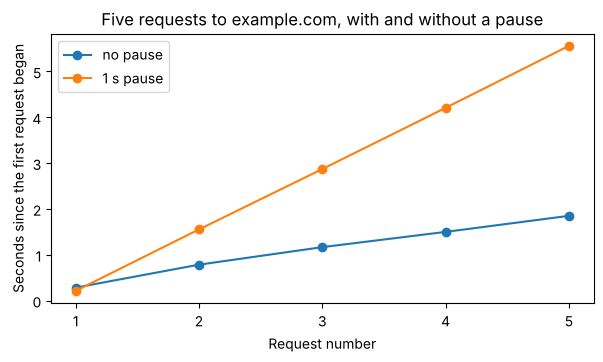

In [16]:
# Plot fast and polite against the request number (1 to 5), with markers,
#   labeled axes, a title, and a legend
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(range(1, 6), fast, marker="o", label="no pause")
ax.plot(range(1, 6), polite, marker="o", label=f"{wait:.0f} s pause")
ax.set_xticks(range(1, 6))
ax.set_xlabel("Request number")
ax.set_ylabel("Seconds since the first request began")
ax.set_title("Five requests to example.com, with and without a pause")
ax.legend()
plt.show()

### ⏱ Microsprint (4 minutes, alone or in pairs)

**Do:** the rest of Additional Exercise 3: run `timed_requests()` with a 2-second delay, and measure the gaps between requests.
**Share:** how long the five requests took, the average gap between them, and how far that is from 2 seconds.

In [17]:
# Microsprint: run timed_requests() on https://example.com/ with a 2-second delay
# Print the total time, and the average gap between requests (pd.Series(...).diff().mean())
slow = timed_requests("https://example.com/", 2)
gap = pd.Series(slow).diff().mean()
print(f"{slow[-1]:.1f} s in all, {gap:.2f} s between requests on average")

9.4 s in all, 2.26 s between requests on average


<details>
<summary>💬 Discuss</summary>

- Five requests with a one-second pause took longer than four seconds of pauses. Where did the rest come from?
- Should the pause count from when a request is sent or from when its answer arrives? Which one is kinder to a slow server?

</details>

## Step 8 — One polite loop (9 minutes)

Every request from here to the end of the course needs the same three things: permission from `robots.txt`, a User-Agent that names us, and a pause. Put them in one loop: for each Times page, ask Step 3's `rp` first; if it says no, skip the page without sending anything; if it says yes, send the request with `HEADERS`, print the status, and wait. The chapter also wraps these habits in a function, `responsible_get()` ([Building a Responsible Scraper Function](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-02-ethics.html#building-a-responsible-scraper-function)), which adds a [`timeout`](https://requests.readthedocs.io/en/latest/user/quickstart/#timeouts) and error handling. Read it there after class; here we keep the loop flat and read the status codes ourselves.

In [18]:
# Make URLS: the Times's /search?query=robots, /section/technology, and home page, as full URLs
# For each url in URLS: if rp.can_fetch("*", url), request it with HEADERS, print the status code and url,
#   and sleep for wait seconds; otherwise print that robots.txt disallows it, without sending anything
URLS = ["https://www.nytimes.com/search?query=robots",
        "https://www.nytimes.com/section/technology",
        "https://www.nytimes.com/"]
for url in URLS:
    if rp.can_fetch("*", url):
        response = requests.get(url, headers=HEADERS)
        print(f"{response.status_code} {url}")
        time.sleep(wait)
    else:
        print(f"skipped {url}: robots.txt disallows it")

skipped https://www.nytimes.com/search?query=robots: robots.txt disallows it


403 https://www.nytimes.com/section/technology


403 https://www.nytimes.com/


### ⏱ Microsprint (3 minutes, alone or in pairs)

**Do:** `response` still holds the loop's last answer, for the Times's home page. Find out who sent it: print its `Server` header and the start of its text.
**Share:** who answered, and what the page asks a visitor to do.

In [19]:
# Microsprint: print response's status code and its "Server" header (response.headers)
# Print the first 240 characters of response.text
print(f"{response.status_code} from {response.headers['Server']}")
print(response.text[:240])

403 from DataDome
<html lang="en"><head><title>nytimes.com</title><style>#cmsg{animation: A 1.5s;}@keyframes A{0%{opacity:0;}99%{opacity:0;}100%{opacity:1;}}</style></head><body style="margin:0"><p id="cmsg">Please enable JS and disable any ad blocker</p><sc


<details>
<summary>💬 Discuss</summary>

- The Times's `robots.txt` allows its section pages for `"*"`, yet the server answered 403. Which signal do you follow, and what does the chapter say to do?
- Week 1 blamed a 403 on a missing User-Agent. We sent one. What else can a 403 mean?
- Our loop assumes every request gets an answer. What would a server that never replied do to it, and which part of `responsible_get()` is there for that?

</details>

## Step 9 — Five questions before you collect (10 minutes)

No code can tell you whether a collection is right. The chapter's [ethical decision framework](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-02-ethics.html#an-ethical-decision-framework) asks five questions before any project: legality, consent, proportionality, privacy, and server impact. Answer them for what we collected today, and keep the answers with the code, the way you'd keep a lab notebook: one sentence each, in a dictionary, printed as a record. Then try the framework on a harder case.

In [20]:
# Make decisions, a dict: its keys are the chapter's five questions (Legality, Consent, Proportionality, Privacy, Server impact),
#   its values one sentence each about what we collected today
# Print each question and its answer, one per line
decisions = {
    "Legality": "robots.txt files and a few public pages, fetched without logging in; no Terms of Service accepted",
    "Consent": "robots.txt is written to be read by machines, so reading it is the use it invites",
    "Proportionality": "we kept only allowed/blocked answers and timings, not page content",
    "Privacy": "no personal data: the files name crawlers and paths, not people",
    "Server impact": "about thirty requests to ten sites, never more than five in a row without a pause",
}
for question, answer in decisions.items():
    print(f"{question}: {answer}")

Legality: robots.txt files and a few public pages, fetched without logging in; no Terms of Service accepted
Consent: robots.txt is written to be read by machines, so reading it is the use it invites
Proportionality: we kept only allowed/blocked answers and timings, not page content
Privacy: no personal data: the files name crawlers and paths, not people
Server impact: about thirty requests to ten sites, never more than five in a row without a pause


### ⏱ Microsprint (6 minutes, in pairs)

**Do:** a short version of Additional Exercise 2: a researcher wants to scrape user profiles from a dating app to study self-presentation across demographic groups. Answer the five questions in a comment line each, then recommend.
**Share:** your recommendation in one sentence, and the question that decided it.

In [21]:
# Microsprint: the dating-app study, one comment line per question, then your recommendation
# Legality: profiles sit behind a login, so the researcher has accepted the app's Terms; after hiQ, contract risk is high
# Consent: users wrote profiles for possible matches, not for researchers; they had no say in this use
# Proportionality: self-presentation could be studied with fewer fields, and without photos or locations
# Privacy: photos, ages, places, and orientations make users easy to re-identify; a breach could out people
# Server impact: small next to the other four, but logged-in scraping is easy for the app to trace to an account
# Recommendation: don't scrape; recruit consenting users (data donation) under IRB review. Consent and privacy decide it.

<details>
<summary>💬 Discuss</summary>

- The chapter says scraping becomes human subjects research when it collects data about identifiable people to produce generalizable knowledge. Does the dating-app study need an IRB, and did ours?
- If some of the app's users live in the EU, what does GDPR add to your answer, wherever the researcher is?
- Week 1's scientific norms asked us to document our methods. Where would `decisions` belong in a paper or a repository?

</details>

## Step 10 — What did we learn? (5 minutes)

In a few sentences, as comments:

- In Step 5, how many of the six newsrooms let GPTBot fetch their home page, and how many let ClaudeBot? What would explain the difference?
- Twice today a tool gave a wrong answer without warning: in Step 3 (in older Pythons) and in Step 4. How did we catch each one?
- In Steps 6 and 7 and the microsprint, how long did five requests take with each delay? Did the pause do what we intended?
- In Step 8, which pages did `robots.txt` allow but the server refuse? What should a responsible scraper do next?

**Recommended Exercises ahead** (in the chapter's companion notebook, due Sunday):

- Step 1, a `HEADERS` dictionary that names the course and your email: Step 0's `HEADERS`, with the course added.
- Step 2, fetch Wikipedia's `robots.txt` and print its status and start: Step 2 fetched the Times's file the same way.
- Step 3, parse it with `rp.parse()` and test three paths: Step 3 parsed the Times's file; Step 4 showed why not `rp.read()`.
- Step 4, two more sites of your choice, fetched politely and counted: Step 5's loop, with `time.sleep(1)`; Step 2 took a file apart line by line.
- Step 5, one DataFrame for all three sites, with `crawl_delay("*")`: Step 5 built a DataFrame from a dict per site; Step 6 read a crawl delay.
- Step 6, interpret: Steps 2 and 5, and their Discuss questions about what a file says of the organization behind it.

In [22]:
# Your answers here, as comments
# Step 5: three of the six newsrooms let GPTBot fetch their home page (the Post, the Journal, the Guardian),
#   and none let ClaudeBot. Those three have announced licensing deals with OpenAI; the Times, which blocks GPTBot,
#   is suing OpenAI (the chapter's case). The file records business deals, not only technical preferences.
# Step 3: the parser said /svc/wordle is allowed, because "Allow: /svc/wordle" (line 75) is longer than
#   "Disallow: /svc" (line 70); Python before 3.14.5 obeyed line 70 and said blocked. We caught it by reading the file.
#   Step 4: read() got a 403 for "Python-urllib/3.14", set disallow_all to True, and said an ordinary article
#   was off limits. We caught it by sending the same User-Agent ourselves and seeing the 403.
# Steps 6-7: five requests took 1.9 s with no pause, 5.6 s with 1 s, and 9.4 s with 2 s (2.26 s apart on
#   average). The pause sets a floor, and each request's own time comes on top of it.
# Step 8: robots.txt allows "*" on /section/technology and the home page, but both got a 403, sent by DataDome,
#   a bot-detection service, with a page that asks for JavaScript. Respect it: don't retry or disguise the client;
#   ask for permission or find an API.

## Friday: from the lab to the textbook (15 minutes)

What did the lab turn up that the chapter should know? Some places to look:

- **Step 3:** the chapter never says that `can_fetch()`'s answers depend on the Python version. Since 3.14.5 the parser follows RFC 9309's longest-match rule; before, it obeyed the first matching rule. Should the chapter say so, and where?
- **Step 2:** the chapter's comparison counts 359 lines in the Times's `robots.txt`. How many did you get? A count that drifts is a reason to date it, or to show how to find it rather than state it.
- **Step 8:** read the chapter's `responsible_get()` beside our loop. It logs its successes with `logging.info()`, which a notebook doesn't show by default. Would that confuse a reader? What one line would make the chapter's function show them?
- **Step 5:** would the AI-crawler table make a good Additional Exercise? Write it as one.
- Any cell that failed for you, or a sentence in the chapter you had to read twice.

[The revision framework](https://github.com/cuinfoscience/INFO4617-Fall2026/blob/main/handouts/common/revision-framework.md) says how to propose a change and what it needs to be accepted.